# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`transformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Він лежить в архіві демо-матеріалів лекції 4 — посилання «Демо-матеріали (zip)» є в картці лекції на головній сторінці курсу. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

### 0.2. Мої відповіді:

**1.** Словник вийшов би майже такий самий: pre-tokenizer однаково ділить текст на слова. Зламалось би інше: весь корпус стає одним рядком у пам'яті, тренер не може обробляти його частинами, тому зростає ризик нестачі пам'яті (OOM).

**2.** Етапи токенізації:
- Normalization — очищення тексту (Unicode, регістр, зайві пробіли).
- Pre-tokenization — поділ тексту на слова.
- Model — поділ слів на токени за словником (BPE, WordPiece, Unigram).
- Post-processing — додавання спеціальних токенів.

**3.** `<unk>` — токен для фрагмента, якого немає у словнику. `<eos>` — токен кінця тексту (вірша).

**4.** Змінив у 2.1: `VOCAB_SIZE = 16000` → `VOCAB_SIZE = 5000`.

| VOCAB_SIZE | токенів у корпусі | токенів на вірш | `<unk>` |
|---|---|---|---|
| 16000 | 18 421 968 | 1028 | 0.0% |
| 5000 | 21 616 329 | 1206 | 0.0% |

Токенів на вірш = токенів у корпусі / 17 918.

`<unk>` не з'являється, бо ByteLevel BPE має у словнику всі 256 байтів, і будь-який текст можна закодувати. Менший словник — менше злиттів, тому слова діляться на дрібніші частини і токенів стає більше. За той самий `CONTEXT_LEN = 64` модель бачить менше тексту.

**5.** `<eos>` позначає межу між віршами. Без нього кінець одного вірша і початок наступного виглядають як один текст: модель вчить хибні переходи між віршами і не вчиться закінчувати текст.

**6.** Це одновимірні тензори `int64`. Кожен елемент — id токена у словнику BPE (від 0 до 15999). `train_data` — перші 90% корпусу, `val_data` — останні 10%.

**7.** Код у клітинці нижче. У демо 3.2 після `xb, yb = get_batch("train")` додаються два `assert`.

**8.** Нижньотрикутна маска дозволяє токену на позиції t бачити лише позиції 0…t, тобто себе і попередні токени. Верхньотрикутна відкрила б майбутні токени. Без маски модель під час тренування бачила б наступний токен і не вчилась би його передбачати. При генерації майбутніх токенів немає, тому текст вийшов би поганим.

**9.** Чекпоінти збігаються, якщо `val_loss` падає до кінця тренування. Не збігаються, якщо модель почала перенавчатись і `val_loss` зріс. У мене найкращий чекпоінт — `iter 7999`, тобто останній: `val_loss` падав увесь час (9.754 → 5.648). Чекпоінти збігаються.

**10.** Змінив у 3.1: `EVAL_INTERVAL = 250` → `EVAL_INTERVAL = 50`.

Час тренування: при 250 — 6.6 хв, при 50 — приблизно 9.6 хв. Тренування повторно не запускав: одна оцінка estimate_loss() займає 1.4 с, при 50 їх 161 замість 33, тобто додатково ≈ 3.0 хв.

Крива: точок стало більше, форма майже та сама.

Менше робити немає сенсу: час росте, а нової інформації крива не дає.

**11.** Temperature ділить логіти перед softmax: p_i = exp(z_i / T) / Σ exp(z_j / T). При T < 1 розподіл гостріший і майже завжди вибирається найімовірніший токен. При T > 1 розподіл рівніший. При дуже великому T всі ймовірності майже однакові, тому токени вибираються майже випадково.

**12.** `top_p` залишає найменший набір найімовірніших токенів, сума ймовірностей яких ≥ p. Наступний токен вибирається тільки з цього набору.

**13.** Змінив у 4.2: `enable_thinking=False` → `enable_thinking=True`.

Результат: модель спершу пише блок міркувань <think> (англійською, аналізує завдання і сумнівається у формулюванні речення), а продовження не встигає видати: max_new_tokens=300 закінчується під час міркувань. При False відповідь була одразу, при True — лише обірвані міркування.

In [ ]:
import torch

CONTEXT_LEN = 64
BATCH_SIZE = 64
data = torch.arange(10_000)

ix = torch.randint(len(data) - CONTEXT_LEN - 1, (BATCH_SIZE,))
xb = torch.stack([data[i:i + CONTEXT_LEN] for i in ix])
yb = torch.stack([data[i + 1:i + CONTEXT_LEN + 1] for i in ix])

assert xb.shape == yb.shape == (BATCH_SIZE, CONTEXT_LEN)
assert torch.equal(xb[:, 1:], yb[:, :-1])
print("OK")

OK


In [ ]:
!pip install "transformers[sentencepiece]==5.18.0"

---
## 1. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

In [ ]:
import os
import sys
import gc
import math
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Використовуємо:", device)

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    LAB_DIR = "/content/drive/MyDrive/lab3"
else:
    LAB_DIR = "lab3"

MODELS_DIR = os.path.join(LAB_DIR, "models")
RUNS_DIR = os.path.join(LAB_DIR, "runs")
RESULTS_PATH = os.path.join(LAB_DIR, "results.csv")
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RUNS_DIR, exist_ok=True)

results = []

Використовуємо: cuda
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from datasets import load_dataset

stream = load_dataset("wikimedia/wikipedia", "20231101.uk", split="train", streaming=True)
rows = list(stream.shuffle(seed=42, buffer_size=10_000).take(20000))
wiki_df = pd.DataFrame(rows)
print("Колонки:", wiki_df.columns.tolist())
print("Статей:", len(wiki_df))

texts = wiki_df["text"].dropna().tolist()
corpus_text = "\n\n".join(texts)
print("Розмір корпусу:", len(corpus_text), "символів")
print(corpus_text[:500])

Колонки: ['id', 'url', 'title', 'text']
Статей: 20000
Розмір корпусу: 46214637 символів
Кубок Кременчу́цького водосховища — спортивні змагання із вітрильного спорту серед крейсерсько-перегонових яхт. Проходять щорічно у містах України, які розташовані на березі Кременчуцького водосховища, створеного на Дніпрі. Організаторами змагань виступають Черкаська та Кіровоградська обласні федерації вітрильного спорту. Започатковані були 1986 року.

Завдання та цілі 
Згідно з регламентом змагання проводяться для:
 популяризації та розвитку вітрильного спорту в Україні;
 підвищенню спортивної 


In [ ]:
words = corpus_text.split()
unique_words = set(w.lower() for w in words)

print("Слів (з повторами):", len(words))
print("Унікальних слів:   ", len(unique_words))
del words, unique_words

Слів (з повторами): 6318215
Унікальних слів:    752123


---
## 2. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Порівняння

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

In [ ]:
from transformers import AutoTokenizer

sample_texts = texts[:2000]
example = "Житомир — місто на півночі України, на річці Тетерів."

old_tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")
new_tokenizer = old_tokenizer.train_new_from_iterator(sample_texts, vocab_size=2000)

print("Старий:", len(old_tokenizer.tokenize(example)), old_tokenizer.tokenize(example))
print("Новий: ", len(new_tokenizer.tokenize(example)), new_tokenizer.tokenize(example))

Старий: 31 ['Ðĸ', 'Ð¸ÑĤ', 'Ð¾Ð¼', 'Ð¸ÑĢ', 'ĠâĢĶ', 'ĠÐ¼', 'Ñĸ', 'ÑģÑĤÐ¾', 'ĠÐ½Ð°', 'ĠÐ¿', 'Ñĸ', 'Ð²', 'Ð½Ð¾', 'Ñĩ', 'Ñĸ', 'ĠÐ£ÐºÑĢÐ°', 'ÑĹ', 'Ð½Ð¸', ',', 'ĠÐ½Ð°', 'ĠÑĢ', 'Ñĸ', 'Ñĩ', 'ÑĨ', 'Ñĸ', 'ĠÐ¢', 'ÐµÑĤ', 'ÐµÑĢ', 'Ñĸ', 'Ð²', '.']
Новий:  20 ['Ðĸ', 'Ð¸ÑĤ', 'Ð¾Ð¼', 'Ð¸ÑĢ', 'ĠâĢĶ', 'ĠÐ¼ÑĸÑģÑĤ', 'Ð¾', 'ĠÐ½Ð°', 'ĠÐ¿ÑĸÐ²', 'Ð½Ð¾', 'ÑĩÑĸ', 'ĠÐ£ÐºÑĢÐ°ÑĹÐ½Ð¸', ',', 'ĠÐ½Ð°', 'ĠÑĢÑĸÑĩ', 'ÑĨÑĸ', 'ĠÐ¢', 'ÐµÑĤ', 'ÐµÑĢÑĸÐ²', '.']


In [ ]:
import re
from tokenizers import Tokenizer, models, trainers, pre_tokenizers

def clean(text):
    text = re.sub(r"[^А-Яа-яІіЇїЄєҐґ0-9 .,!?:;()\-—«»'’\n]", "", text)
    return re.sub(r" +", " ", text)

train_texts = [clean(t) for t in texts[:2000]]
eval_texts = [clean(t) for t in texts[2000:2200]]

VOCAB = 500

def build(algo):
    if algo == "BPE":
        tok = Tokenizer(models.BPE(unk_token="[UNK]"))
        trainer = trainers.BpeTrainer(vocab_size=VOCAB, special_tokens=["[UNK]"])
    elif algo == "WordPiece":
        tok = Tokenizer(models.WordPiece(unk_token="[UNK]"))
        trainer = trainers.WordPieceTrainer(vocab_size=VOCAB, special_tokens=["[UNK]"])
    else:
        tok = Tokenizer(models.Unigram())
        trainer = trainers.UnigramTrainer(vocab_size=VOCAB, special_tokens=["[UNK]"], unk_token="[UNK]")
    tok.pre_tokenizer = pre_tokenizers.Whitespace()
    tok.train_from_iterator(train_texts, trainer=trainer)
    return tok

toks = {algo: build(algo) for algo in ["BPE", "WordPiece", "Unigram"]}

In [ ]:
FREQUENT_WORD = "України"
RARE_WORD = "електроенцефалографія"

table = []
for algo, tok in toks.items():
    n_tokens = sum(len(e.ids) for e in tok.encode_batch(eval_texts))
    table.append({
        "алгоритм": algo,
        "розмір словника": tok.get_vocab_size(),
        "токенів на зразку": n_tokens,
        FREQUENT_WORD: tok.encode(FREQUENT_WORD).tokens,
        RARE_WORD: tok.encode(RARE_WORD).tokens,
    })

display(pd.DataFrame(table))

,алгоритм,розмір словника,токенів на зразку,України,електроенцефалографія
0,BPE,500,205478,[України],"[е, лек, тро, ен, це, фа, ло, гра, фі, я]"
1,WordPiece,500,227504,[України],"[е, ##ле, ##к, ##т, ##ро, ##ен, ##ц, ##е, ##ф,..."
2,Unigram,500,215428,[України],"[е, лек, тро, ен, це, фа, ло, граф, і, я]"


Висновок: найкоротші послідовності дав BPE (205 478 токенів на зразку), далі Unigram (215 428) і WordPiece (227 504). Це узгоджується з туторіалом: BPE зливає найчастіші пари і найкраще стискає частий текст, а WordPiece ділить рідкісні слова на найдрібніші частини.

---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).

### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

In [ ]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

VOCAB_SIZE = 16000
SPECIAL_TOKENS = ["<unk>", "<eos>"]

tokenizer = Tokenizer(models.BPE(unk_token="<unk>"))
tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
tokenizer.decoder = decoders.ByteLevel()

trainer = trainers.BpeTrainer(vocab_size=VOCAB_SIZE, special_tokens=SPECIAL_TOKENS)
tokenizer.train_from_iterator(texts, trainer=trainer)
tokenizer.save(os.path.join(MODELS_DIR, "tokenizer.json"))
print("Розмір словника:", tokenizer.get_vocab_size())

Розмір словника: 16000


In [ ]:
EOS_ID = tokenizer.token_to_id("<eos>")
UNK_ID = tokenizer.token_to_id("<unk>")

chunks = []
for start in range(0, len(texts), 1000):
    for enc in tokenizer.encode_batch(texts[start:start + 1000]):
        chunks.append(np.array(enc.ids + [EOS_ID], dtype=np.int32))
token_ids = np.concatenate(chunks)
del chunks
gc.collect()

print("Токенів у корпусі:", len(token_ids))
print(f"Токенів <unk>: {(token_ids == UNK_ID).mean():.1%}")

data = torch.from_numpy(token_ids.astype(np.int64))
del token_ids
gc.collect()

split_idx = int(len(data) * 0.9)
train_data = data[:split_idx]
val_data = data[split_idx:]
print("train:", train_data.shape, " val:", val_data.shape)

Токенів у корпусі: 13210978
Токенів <unk>: 0.0%
train: torch.Size([11889880])  val: torch.Size([1321098])


In [ ]:
class AttentionHead(nn.Module):
    def __init__(self, embed_dim, head_dim, context_len, dropout):
        super().__init__()
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("causal_mask", torch.tril(torch.ones(context_len, context_len)))

    def forward(self, x):
        B, T, C = x.shape
        q = self.query(x)
        k = self.key(x)
        v = self.value(x)
        scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])
        scores = scores.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        weights = self.dropout(F.softmax(scores, dim=-1))
        return weights @ v


class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim, n_heads, context_len, dropout):
        super().__init__()
        head_dim = embed_dim // n_heads
        self.heads = nn.ModuleList([
            AttentionHead(embed_dim, head_dim, context_len, dropout) for _ in range(n_heads)
        ])
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([head(x) for head in self.heads], dim=-1)
        return self.dropout(self.proj(out))


class FeedForward(nn.Module):
    def __init__(self, embed_dim, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, embed_dim, n_heads, context_len, dropout):
        super().__init__()
        self.attention = MultiHeadAttention(embed_dim, n_heads, context_len, dropout)
        self.feed_forward = FeedForward(embed_dim, dropout)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.feed_forward(self.norm2(x))
        return x


class MiniGPT(nn.Module):
    def __init__(self, vocab_size, embed_dim, n_heads, n_layers, context_len, dropout):
        super().__init__()
        self.context_len = context_len
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(context_len, embed_dim)
        self.blocks = nn.Sequential(*[
            TransformerBlock(embed_dim, n_heads, context_len, dropout) for _ in range(n_layers)
        ])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding(idx)
        pos_emb = self.position_embedding(torch.arange(T, device=idx.device))
        x = self.final_norm(self.blocks(tok_emb + pos_emb))
        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        self.eval()
        for _ in range(max_new_tokens):
            logits, _ = self(idx[:, -self.context_len:])
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = float("-inf")
            next_id = torch.multinomial(F.softmax(logits, dim=-1), num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx

In [ ]:
BASE_CONFIG = dict(
    CONTEXT_LEN=64,
    EMBED_DIM=128,
    N_HEADS=4,
    N_LAYERS=4,
    DROPOUT=0.1,
    BATCH_SIZE=64,
    LEARNING_RATE=3e-4,
    MAX_ITERS=8000,
    EVAL_INTERVAL=250,
    EVAL_ITERS=50,
)

VARIANTS = {
    "v1": ("baseline", {}),
    "v2": ("layers6", {"N_LAYERS": 6}),
}

In [ ]:
from torch.utils.tensorboard import SummaryWriter

def get_batch(split, cfg):
    source = train_data if split == "train" else val_data
    ix = torch.randint(len(source) - cfg["CONTEXT_LEN"] - 1, (cfg["BATCH_SIZE"],))
    x = torch.stack([source[i:i + cfg["CONTEXT_LEN"]] for i in ix])
    y = torch.stack([source[i + 1:i + cfg["CONTEXT_LEN"] + 1] for i in ix])
    return x.to(device), y.to(device)


@torch.no_grad()
def estimate_loss(model, cfg):
    model.eval()
    out = {}
    for split in ("train", "val"):
        losses = torch.zeros(cfg["EVAL_ITERS"])
        for i in range(cfg["EVAL_ITERS"]):
            xb, yb = get_batch(split, cfg)
            _, loss = model(xb, yb)
            losses[i] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out


def build_model(cfg):
    return MiniGPT(tokenizer.get_vocab_size(), cfg["EMBED_DIM"], cfg["N_HEADS"],
                   cfg["N_LAYERS"], cfg["CONTEXT_LEN"], cfg["DROPOUT"]).to(device)


def train(name, desc, cfg):
    torch.manual_seed(42)
    model = build_model(cfg)
    n_params = sum(p.numel() for p in model.parameters())
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["LEARNING_RATE"])
    writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, f"{name}_{desc}"))
    ckpt_path = os.path.join(MODELS_DIR, f"minigpt_{name}.pt")

    history = {"iter": [], "train": [], "val": []}
    best_val_loss, best_iter = float("inf"), None
    start_time = time.time()

    for it in range(cfg["MAX_ITERS"]):
        xb, yb = get_batch("train", cfg)
        _, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        if it % cfg["EVAL_INTERVAL"] == 0 or it == cfg["MAX_ITERS"] - 1:
            losses = estimate_loss(model, cfg)
            history["iter"].append(it)
            history["train"].append(losses["train"])
            history["val"].append(losses["val"])
            writer.add_scalar("Loss/train", losses["train"], it)
            writer.add_scalar("Loss/val", losses["val"], it)

            if it % 1000 == 0 or it == cfg["MAX_ITERS"] - 1:
                print(f"[{name}] iter {it:5d}  train_loss={losses['train']:.3f}  "
                      f"val_loss={losses['val']:.3f}  ({(time.time() - start_time) / 60:.1f} хв)")

            if losses["val"] < best_val_loss:
                best_val_loss, best_iter = losses["val"], it
                torch.save(model.state_dict(), ckpt_path)

    writer.close()
    minutes = (time.time() - start_time) / 60
    print(f"[{name}] найкращий чекпоінт: iter {best_iter}, val_loss={best_val_loss:.3f}, {minutes:.1f} хв\n")
    return {"desc": desc, "cfg": cfg, "params": n_params, "best_val_loss": best_val_loss,
            "best_iter": best_iter, "minutes": minutes, "history": history}


summaries = {}
for name, (desc, changes) in VARIANTS.items():
    summaries[name] = train(name, desc, {**BASE_CONFIG, **changes})

[v1] iter     0  train_loss=9.801  val_loss=9.802  (0.0 хв)
[v1] iter  1000  train_loss=6.867  val_loss=6.854  (0.8 хв)
[v1] iter  2000  train_loss=6.167  val_loss=6.204  (1.7 хв)
[v1] iter  3000  train_loss=5.784  val_loss=5.849  (2.8 хв)
[v1] iter  4000  train_loss=5.512  val_loss=5.590  (3.7 хв)
[v1] iter  5000  train_loss=5.308  val_loss=5.381  (4.6 хв)
[v1] iter  6000  train_loss=5.164  val_loss=5.242  (5.5 хв)
[v1] iter  7000  train_loss=5.069  val_loss=5.163  (6.3 хв)
[v1] iter  7999  train_loss=4.978  val_loss=5.114  (7.2 хв)
[v1] найкращий чекпоінт: iter 7500, val_loss=5.080, 7.2 хв

[v2] iter     0  train_loss=9.753  val_loss=9.754  (0.0 хв)
[v2] iter  1000  train_loss=6.721  val_loss=6.771  (1.1 хв)
[v2] iter  2000  train_loss=6.108  val_loss=6.116  (2.1 хв)
[v2] iter  3000  train_loss=5.736  val_loss=5.747  (3.2 хв)
[v2] iter  4000  train_loss=5.437  val_loss=5.465  (4.2 хв)
[v2] iter  5000  train_loss=5.233  val_loss=5.292  (5.3 хв)
[v2] iter  6000  train_loss=5.092  val_l

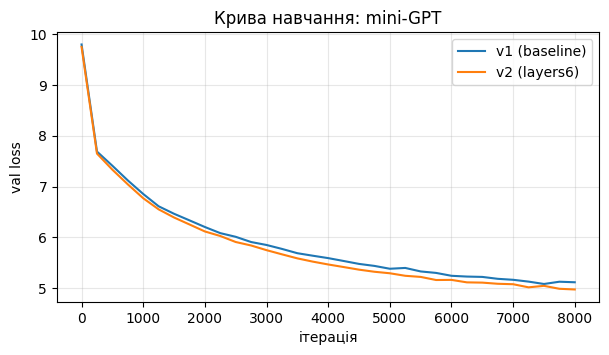

In [ ]:
plt.figure(figsize=(7, 3.5))
for name, s in summaries.items():
    plt.plot(s["history"]["iter"], s["history"]["val"], label=f"{name} ({s['desc']})")
plt.xlabel("ітерація"); plt.ylabel("val loss"); plt.title("Крива навчання: mini-GPT")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [ ]:
PROMPT = "Україна — держава"

for name, s in summaries.items():
    model = build_model(s["cfg"])
    model.load_state_dict(torch.load(os.path.join(MODELS_DIR, f"minigpt_{name}.pt"), map_location=device))
    prompt_ids = torch.tensor([tokenizer.encode(PROMPT).ids], dtype=torch.long, device=device)
    torch.manual_seed(42)
    out_ids = model.generate(prompt_ids, max_new_tokens=60, temperature=0.8, top_k=40)
    print(f"=== {name} ({s['desc']}), val_loss={s['best_val_loss']:.3f} ===")
    print(tokenizer.decode(out_ids[0].tolist()), "\n")

=== v1 (baseline), val_loss=5.080 ===
Україна — держава

У 2004 році 
Вшанування пам'ятдесятих.

Примітки

Джерела 

Ботанічні пам'ятки природи Закарпатської області
Природоохоронні об'єкти, засновані 1984Хай () — громада в Німеччині, розташована в землі Тюрингія. Входить до складу району Бітбург-Пфальц 

=== v2 (layers6), val_loss=4.972 ===
Україна — держава 

У 2004 році

Нагороди 
За особисту мужність та територіальної цілісності України, виявлені у захисті державного суверенітету та територіальної цілісності України, вірність військовій присязі нагороджений орденом «За мужність» III ступеня (посмертно).

До початку XX століття 

Доробок по липень 2015 року.

Див 



In [ ]:
for name, s in summaries.items():
    results.append({
        "section": "mini-gpt",
        "model": f"minigpt_{name}",
        "setting": s["desc"],
        "metric": "val_loss",
        "value": round(s["best_val_loss"], 4),
        "params": s["params"],
        "best_iter": s["best_iter"],
        "train_minutes": round(s["minutes"], 1),
    })

pd.DataFrame(results).to_csv(RESULTS_PATH, index=False)
display(pd.DataFrame(results))

,section,model,setting,metric,value,params,best_iter,train_minutes
0,mini-gpt,minigpt_v1,baseline,val_loss,5.0805,4912000,7500,7.2
1,mini-gpt,minigpt_v2,layers6,val_loss,4.9722,5307776,7999,8.4


Висновок: кращий val_loss дав v2 з 6 шарами (4.972 проти 5.080 у v1). За текстом різниця невелика: обидва варіанти видають вікіподібний текст, у v2 речення трохи зв'язніші. Найбільший ефект дала зміна глибини мережі.

---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

_Зверніть увагу_: в межах попередніх завдань Ви могли завантажити памʼять "під завʼязку", тому для безпроблемного виконання наступних секцій вивільніть памʼять:

1. **Спершу збережіть усе потрібне на диск** — чекпоінти mini-GPT (`models/minigpt_v*.pt`), токенізатори, `results.csv`. Секції 4-6 від змінних секцій 1-3 не залежать, тож після цього їх можна сміливо видаляти.
2. **Видаліть великі обʼєкти** — моделі, оптимізатори, тензори `train_data`/`val_data`, корпус і `DataFrame`-и — і зберіть сміття:
   ```python
   import gc, torch

   del model, optimizer, train_data, val_data, corpus_text  # підставте свої імена змінних
   gc.collect()
   if torch.cuda.is_available():
       torch.cuda.empty_cache()
       print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
   ```
   Памʼять звільниться лише тоді, коли на обʼєкт не лишиться **жодного** посилання: зверніть увагу на копії в інших змінних, списках і словниках (наприклад, словник із кількома варіантами моделей).
3. **Перевірте, що памʼять справді звільнилась**: індикатор RAM/GPU вгорі праворуч.
4. **У самій секції 4 не тримайте всі pipeline-и одночасно**: кожен `pipeline(...)` завантажує окрему модель. Перевикористовуйте одну змінну (як `classifier` нижче) або робіть `del` + `gc.collect()` після кожної задачі.
5. **Стежте за диском**: моделі кешуються в `~/.cache/huggingface/hub`, і кілька моделей для summarization/translation легко займуть кілька ГБ. Переглянути й почистити кеш: `hf cache ls` / `hf cache rm <id моделі>`.

In [ ]:
import gc

del model, train_data, val_data, data, corpus_text, texts, wiki_df, rows

def free():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")

free()

GPU: зайнято 0.02 GB


### 4.0. Запустіть приклади виконання різних NLP задач

In [ ]:
!pip install "transformers[sentencepiece]==5.18.0"

In [ ]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
))

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9598046541213989}]
[{'label': 'POSITIVE', 'score': 0.9598046541213989}, {'label': 'NEGATIVE', 'score': 0.9994558691978455}]


In [ ]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification")
classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"],
)

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.844595193862915, 0.11197695881128311, 0.04342786595225334]}

In [ ]:
# Text generation
from transformers import pipeline

generator = pipeline("text-generation")
print(generator("In this course, we will teach you how to"))

generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_length=30,
    num_return_sequences=2,
))

[transformers] No model was supplied, defaulted to HuggingFaceTB/SmolLM3-3B and revision a07cc9a.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/26.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'num_return_sequences', 'max_length'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': "In this course, we will teach you how to use this material in your own practice. We'll teach you how to use this material in your own practice.\n\n\n\nThe main thing to do here is to use your own terminology. Your own words will be used in terms of the meaning of the words as they are used.\nI will provide you with the following instructions:\n1. When you start using the word in your own practice, you will only use the word 'a' if you use the word 'a' when you are using it. This is the last time you use it, and you will only use the word 'a' if you use it.\n2. When you start using the word in your own practice, you will only use the word 'a' if you use it. This is the last time you use it, and you will only use the word 'a' when you are using it. This is the last time you use it, and you will only use the word 'a' when you are using it. This is the last time you use it, and you will only use the word 'a' when you are using it.\n3. When you start using the word in y

In [ ]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask")
unmasker("This course will teach you all about <mask> models.", top_k=2)

[transformers] No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'score': 0.19619743525981903,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.04052695631980896,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

In [ ]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", aggregation_strategy="simple")
ner("My name is Sylvain and I work at Hugging Face in Brooklyn.")

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9796019),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

In [ ]:
# Question answering
from transformers import pipeline

question_answerer = pipeline("table-question-answering")
question_answerer(
    query="How many stars does the transformers repository have?",
    table={"Repository":["Transformers","Datasets","Tokenizers"],"Stars":["36542","4512","3934"],"Contributors":["651","77","34"],"Programming language":["Python","Python","Rust, Python and NodeJS"]},
)

[transformers] No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.66k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

vocab.txt:   0%|          | 0.00/262k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/154 [00:00<?, ?B/s]

{'answer': 'AVERAGE > 36542',
 'coordinates': [(0, 1)],
 'cells': ['36542'],
 'aggregator': 'AVERAGE'}

### 4.1. Свої приклади

Повторіть усі 6 задач вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, table-question-answering), але замість дефолтних англійських прикладів — придумайте й використайте свої українськомовні приклади для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

In [ ]:
# Sentiment analysis
clf = pipeline("sentiment-analysis", model="cardiffnlp/twitter-xlm-roberta-base-sentiment", device=device)
print(clf([
    "Це був чудовий фільм, я отримав справжнє задоволення!",
    "Сервіс жахливий, більше ніколи сюди не прийду.",
]))
del clf; free()

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

[{'label': 'positive', 'score': 0.9369524121284485}, {'label': 'negative', 'score': 0.9346151947975159}]
GPU: зайнято 4.08 GB


In [ ]:
# Zero-shot classification
clf = pipeline("zero-shot-classification",
               model="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7", device=device)
print(clf(
    "Збірна України здобула перемогу в півфіналі чемпіонату.",
    candidate_labels=["політика", "спорт", "освіта", "економіка"],
))
del clf; free()

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

{'sequence': 'Збірна України здобула перемогу в півфіналі чемпіонату.', 'labels': ['спорт', 'освіта', 'політика', 'економіка'], 'scores': [0.9537265300750732, 0.026713833212852478, 0.014980530366301537, 0.004579133354127407]}
GPU: зайнято 4.08 GB


In [ ]:
# Text generation
generator = pipeline("text-generation", model="Qwen/Qwen2.5-0.5B-Instruct", device=device)
print(generator(
    "Продовж історію: Одного ранку в Житомирі випав перший сніг, і",
    max_new_tokens=50,
    num_return_sequences=2,
))
del generator; free()

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'num_return_sequences', 'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=50) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': 'Продовж історію: Одного ранку в Житомирі випав перший сніг, іншого - в Германи. Другий - в Польщі, та третий - в Італії.\n\nTranslate to English\n\nEnglish:\n\nThe longest stretch of the Polish–Lithuanian'}, {'generated_text': "Продовж історію: Одного ранку в Житомирі випав перший сніг, історична відновлення є відбулася. Наприклад, більшість після цього країни зв'язано з Вели"}]
GPU: зайнято 3.75 GB


In [ ]:
# Fill-mask
unmasker = pipeline("fill-mask", model="xlm-roberta-base", device=device)
print(unmasker("Київ — столиця <mask>.", top_k=3))
del unmasker; free()

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] XLMRobertaForMaskedLM LOAD REPORT from: xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

[{'score': 0.44054076075553894, 'token': 2513, 'token_str': 'України', 'sequence': 'Київ — столиця України .'}, {'score': 0.08850615471601486, 'token': 5, 'token_str': '.', 'sequence': 'Київ — столиця. .'}, {'score': 0.05313568189740181, 'token': 28105, 'token_str': 'Україна', 'sequence': 'Київ — столиця Україна .'}]
GPU: зайнято 3.42 GB


In [ ]:
# Named entity recognition
ner = pipeline("ner", model="Davlan/xlm-roberta-base-ner-hrl", aggregation_strategy="simple", device=device)
print(ner("Тарас Шевченко народився в селі Моринці, а навчався в Петербурзі."))
del ner; free()

config.json:   0%|          | 0.00/980 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/211 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

[{'entity_group': 'PER', 'score': np.float32(0.99984336), 'word': 'Тарас Шевченко', 'start': 0, 'end': 14}, {'entity_group': 'LOC', 'score': np.float32(0.9663488), 'word': 'Моринці', 'start': 32, 'end': 39}, {'entity_group': 'LOC', 'score': np.float32(0.9953231), 'word': 'Петербурзі', 'start': 54, 'end': 64}]
GPU: зайнято 2.09 GB


In [ ]:
# Question answering
question_answerer = pipeline("table-question-answering", model="google/tapas-base-finetuned-wtq", device=device)
print(question_answerer(
    query="Яке населення Житомира?",
    table={"Місто": ["Київ", "Львів", "Житомир"], "Населення": ["2950000", "720000", "260000"]},
))
del question_answerer; free()

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

{'answer': 'AVERAGE > 260000', 'coordinates': [(2, 1)], 'cells': ['260000'], 'aggregator': 'AVERAGE'}
GPU: зайнято 1.65 GB


---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

In [ ]:
!pip install -q evaluate

In [ ]:
import evaluate

sentences = [
    "Дуже смачна їжа і привітний персонал, обов'язково повернемося!",
    "Чудовий фільм, я не міг відірватися від екрана до самого кінця.",
    "Лекція була цікавою, викладач пояснив усе зрозуміло.",
    "Доставка прийшла раніше терміну, товар якісний.",
    "Нарешті склав іспит із першого разу, я дуже щасливий!",
    "Готель чистий, номери затишні, вид з вікна чудовий.",
    "Дякую за швидку допомогу, ви мене дуже виручили.",
    "Це найкраща книжка, яку я читав за останні роки.",
    "Застосунок працює швидко й зручний у користуванні.",
    "Прогулянка парком у сонячний день зарядила мене енергією.",
    "Обслуговування жахливе, довелося чекати на замовлення дві години.",
    "Фільм нудний і передбачуваний, шкода часу.",
    "Лекція була безглуздою, я нічого не зрозумів.",
    "Товар прийшов зламаним, а підтримка не відповідає.",
    "Знову провалив залік, настрій на нулі.",
    "У номері брудно, ліжко незручне, всю ніч не спав.",
    "Дуже розчарований, це повна втрата грошей.",
    "Книжка затягнута, ледве дочитав.",
    "Застосунок постійно вилітає, користуватися неможливо.",
    "Цілий день ішов дощ, я змок і застудився.",
]
labels = [1] * 10 + [0] * 10

accuracy = evaluate.load("accuracy")
f1 = evaluate.load("f1")

LABEL_NAMES = {"label_0": "negative", "label_1": "neutral", "label_2": "positive"}

def predict(scores, threshold=None):
    preds = []
    for s in scores:
        if threshold is None:
            preds.append(int(max(s, key=s.get) == "positive"))
        else:
            preds.append(int(s["positive"] / (s["positive"] + s["negative"]) >= threshold))
    return preds

def get_metrics(preds):
    acc = accuracy.compute(predictions=preds, references=labels)["accuracy"]
    f1_value = f1.compute(predictions=preds, references=labels)["f1"]
    return round(acc, 3), round(f1_value, 3)

In [ ]:
SENTIMENT_MODELS = {
    "xlm-roberta": "cardiffnlp/twitter-xlm-roberta-base-sentiment",
    "distilbert": "lxyuan/distilbert-base-multilingual-cased-sentiments-student",
}

all_scores = {}
comparison = []
for name, model_id in SENTIMENT_MODELS.items():
    clf = pipeline("text-classification", model=model_id, top_k=None, device=device)
    params = clf.model.num_parameters()
    clf(sentences[:2])

    start_time = time.time()
    out = clf(sentences)
    ms_per_text = (time.time() - start_time) / len(sentences) * 1000

    all_scores[name] = [
        {LABEL_NAMES.get(d["label"].lower(), d["label"].lower()): d["score"] for d in item} for item in out
    ]
    acc, f1_value = get_metrics(predict(all_scores[name]))
    comparison.append({"модель": name, "accuracy": acc, "f1": f1_value,
                       "параметрів, млн": round(params / 1e6), "мс на речення": round(ms_per_text, 1)})
    del clf; free()

display(pd.DataFrame(comparison))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

GPU: зайнято 1.65 GB


config.json:   0%|          | 0.00/759 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

...

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

GPU: зайнято 1.65 GB


,модель,accuracy,f1,"параметрів, млн",мс на речення
0,xlm-roberta,1.00,1.000,278,12.2
1,distilbert,0.75,0.706,135,6.3


In [ ]:
SETTINGS = {
    "argmax по 3 класах": None,
    "поріг 0.3": 0.3,
    "поріг 0.5": 0.5,
    "поріг 0.7": 0.7,
}

settings_table = []
for name, scores in all_scores.items():
    for setting, threshold in SETTINGS.items():
        acc, f1_value = get_metrics(predict(scores, threshold))
        settings_table.append({"модель": name, "налаштування": setting, "accuracy": acc, "f1": f1_value})
        results.append({"section": "sentiment", "model": SENTIMENT_MODELS[name], "setting": setting,
                        "metric": "accuracy", "value": acc, "f1": f1_value})

pd.DataFrame(results).to_csv(RESULTS_PATH, index=False)
display(pd.DataFrame(settings_table))

,модель,налаштування,accuracy,f1
0,xlm-roberta,argmax по 3 класах,1.00,1.000
1,xlm-roberta,поріг 0.3,1.00,1.000
2,xlm-roberta,поріг 0.5,1.00,1.000
3,xlm-roberta,поріг 0.7,1.00,1.000
4,distilbert,argmax по 3 класах,0.75,0.706
5,distilbert,поріг 0.3,0.70,0.750
6,distilbert,поріг 0.5,0.75,0.706
7,distilbert,поріг 0.7,0.70,0.571


Висновок: найкращий результат дала модель xlm-roberta з будь-яким налаштуванням (accuracy 1.0, f1 1.0). Вибір моделі вплинув на метрику сильно (1.0 проти 0.75 у distilbert), налаштування слабко (0.70–0.75 у distilbert).

---
## 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

**Тон-метр листа.** Застосунок оцінює, як звучить повідомлення (ввічливо, різко, емоційно тощо), перш ніж його надіслати викладачеві чи в деканат. Модель — mDeBERTa (zero-shot) з розділу 4.

In [ ]:
!pip install -q gradio

import torch
import gradio as gr
from transformers import pipeline

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

zero_shot = pipeline("zero-shot-classification",
                     model="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7", device=device)

TONES = ["ввічливий", "офіційний", "емоційний", "різкий", "невпевнений"]

TIPS = {
    "ввічливий": "Тон нормальний, можна надсилати.",
    "офіційний": "Тон нормальний, можна надсилати.",
    "емоційний": "Забагато емоцій. Залиште факти й конкретне прохання.",
    "різкий": "Звучить різко. Додайте привітання й м'якші формулювання.",
    "невпевнений": "Звучить непевно. Сформулюйте прохання прямо.",
}

def analyze(text):
    out = zero_shot(text, candidate_labels=TONES,
                    hypothesis_template="Тон цього повідомлення: {}.", multi_label=True)
    scores = dict(zip(out["labels"], out["scores"]))
    return scores, TIPS[out["labels"][0]]

app = gr.Interface(
    fn=analyze,
    inputs=gr.Textbox(lines=6, label="Текст повідомлення"),
    outputs=[gr.Label(label="Тон"), gr.Textbox(label="Порада")],
    title="Тон-метр листа",
    examples=[
        ["Доброго дня! Підкажіть, будь ласка, коли можна перездати лабораторну? Дякую."],
        ["Ви не пояснили тему, а тепер ставите двійки. Це несправедливо!"],
    ],
)
app.launch()

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0d04cac9fb2bc4a37b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу

У [форму](https://forms.gle/Z1gxmsDs656jqsDGA) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```